# Bloque 4

En los ítems $4.1$ a $4.3$ usamos los experimentos tamanos y desorden, y cada lista medida es una observación de la regresión. Para el ítem $4.4$ debera generar un nuevo set de listas de simulación variando el valor de $k$

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels.api as sm
from codigo_base import medir

# Estilo de los gráficos
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.titlesize": 11,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "legend.fontsize": 9,
})
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#52514e"

# Variables globales
rng = np.random.default_rng(4)

## Ejercicio 4.1

Complejidad de insertion sort. Con las mediciones para $n = 10, 20, 50, 100, 200, 500, 1000$, grafique $S_n$ en función de $n$ y muestre que la dependencia no es lineal.

observaciones por n: [200, 200, 200, 200, 200, 200, 200]


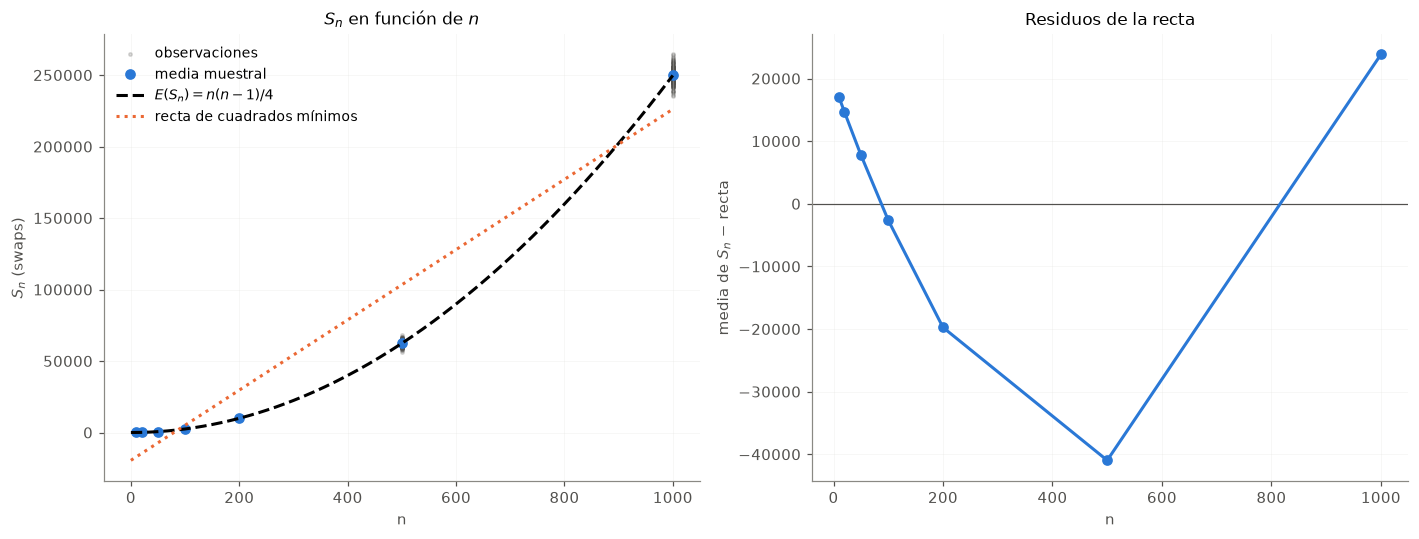

,media de S_n,media de S_n / n,(n − 1) / 4
n,,,
10,21.70,2.17,2.25
20,95.27,4.76,4.75
50,613.25,12.26,12.25
100,2466.42,24.66,24.75
200,9908.94,49.54,49.75
500,62365.36,124.73,124.75
1000,249982.92,249.98,249.75


In [2]:
ns = [10, 20, 50, 100, 200, 500, 1000]
sn_tamanos = {m: [] for m in ns}        # S_n 
qn_tamanos = {m: [] for m in ns}        # Q_n 

conteosJSON = open("conteos.jsonl", "r")

for linea in conteosJSON:
    datos = json.loads(linea)
    if datos["experimento"] == "tamanos":
        if datos["algoritmo"] == "insertion":
            sn_tamanos[datos["n"]].append(datos["swaps"])
        elif datos["algoritmo"] == "quick_primero":
            qn_tamanos[datos["n"]].append(datos["comparaciones"])

conteosJSON.close()

print("observaciones por n:", [len(sn_tamanos[m]) for m in ns])

# S_n en función de n
sn_medias = np.array([np.mean(sn_tamanos[m]) for m in ns])
x_obs = np.concatenate([np.full(len(sn_tamanos[m]), m) for m in ns])
y_obs = np.concatenate([sn_tamanos[m] for m in ns])

b, a = np.polyfit(x_obs, y_obs, 1)                  # recta S = a + b n sobre todas las observaciones
residuos_recta = sn_medias - (a + b * np.array(ns))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.scatter(x_obs, y_obs, s=5, alpha=0.2, color=GRIS, label="observaciones")
ax1.plot(ns, sn_medias, "o", color=AZUL, label="media muestral")
grilla = np.linspace(0, 1000, 300)
ax1.plot(grilla, grilla * (grilla - 1) / 4, "k--", label=r"$E(S_n)=n(n-1)/4$")
ax1.plot(grilla, a + b * grilla, ":", color=NARANJA, lw=2, label="recta de cuadrados mínimos")
ax1.set_xlabel("n"); ax1.set_ylabel(r"$S_n$ (swaps)")
ax1.set_title(r"$S_n$ en función de $n$")
ax1.legend(); ax1.grid(alpha=0.3)

ax2.axhline(0, color=GRIS, lw=0.8)
ax2.plot(ns, residuos_recta, "o-", color=AZUL)
ax2.set_xlabel("n"); ax2.set_ylabel(r"media de $S_n$ − recta")
ax2.set_title("Residuos de la recta")
ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Si la dependencia fuera lineal, S_n / n sería constante
pd.DataFrame({"media de S_n": sn_medias,
              "media de S_n / n": sn_medias / np.array(ns),
              "(n − 1) / 4": (np.array(ns) - 1) / 4},
             index=pd.Index(ns, name="n")).round(2)


La dependencia de $S_n$ con $n$ no es lineal. Si lo fuera, el cociente $S_n/n$ sería constante, pero crece con $n$: pasa de $2{,}17$ con $n = 10$ a $24{,}66$ con $n = 100$ y a $249{,}98$ con $n = 1000$, siguiendo a $(n-1)/4 = \mathrm{E}(S_n)/n$.

En el gráfico las medias muestrales caen sobre la curva $\mathrm{E}(S_n) = n(n-1)/4$ y se apartan de la recta de cuadrados mínimos. Los residuos de la recta tienen forma de U, que es lo que pasa al ajustar una recta a una curva convexa: son positivos para $n$ chico (la recta predice unos $-17\,000$ swaps, un valor imposible), negativos en el medio (unos $-40\,000$ con $n = 500$) y positivos otra vez con $n = 1000$. Es el crecimiento cuadrático: al multiplicar $n$ por 10, $S_n$ se multiplica por casi 100 y no por 10.

### a)

A partir de la fórmula de $E(S_n)$, ¿qué valores de $\beta_0$ y $\beta_1$ espera para $n$ grande en la regresión ln $S_n = \beta_0 + \beta_1 ln( n )+ \epsilon$? Ajústela y construya intervalos de confianza de nivel $0,95$ para $\beta_0$ y $\beta_1$. Contraste $H_0 : \beta_1 = 2$ usando todos los $n$ ($1400$ observaciones) y usando solo $n \geq 100$ ($800$ observaciones).

---

Como $\mathrm{E}(S_n) = \dfrac{n(n-1)}{4} = \dfrac{n^2}{4}\left(1 - \dfrac{1}{n}\right)$, tomando logaritmo
$$\ln \mathrm{E}(S_n) = 2\ln n - \ln 4 + \ln\left(1 - \tfrac{1}{n}\right).$$
Para $n$ grande el último término tiende a 0, así que esperamos $\beta_1 = 2$ y $\beta_0 = -\ln 4 \approx -1{,}386$.

Ajustamos la recta con las observaciones individuales: cada lista es un punto $(\ln n, \ln S_n)$, con 200 listas por cada $n$. Los intervalos son $\hat\beta_j \pm t_{N-2;\,0{,}975}\,\mathrm{EE}(\hat\beta_j)$, y para el test usamos $T = (\hat\beta_1 - 2)/\mathrm{EE}(\hat\beta_1)$, que bajo $H_0$ tiene distribución $t_{N-2}$.

In [3]:

def datos_loglog(ms):
    x = np.concatenate([np.full(len(sn_tamanos[m]), np.log(m)) for m in ms])
    y = np.log(np.concatenate([sn_tamanos[m] for m in ms]))
    return x, y

ns_100 = [m for m in ns if m >= 100]
x_todos, y_todos = datos_loglog(ns)
x_100, y_100 = datos_loglog(ns_100)
r_todos = sm.OLS(y_todos, sm.add_constant(x_todos)).fit()
r_100 = sm.OLS(y_100, sm.add_constant(x_100)).fit()

def fila_regresion(r, nombre):
    (b0, b1), (se0, se1) = r.params, r.bse
    ic0, ic1 = r.conf_int(alpha=0.05)                
    t1 = (b1 - 2) / se1                              
    p1 = 2 * stats.t.sf(abs(t1), r.df_resid)
    return {"Ajuste": nombre, "N": int(r.nobs),
            "β̂0": b0, "IC 95 % β0": f"[{ic0[0]:.3f}, {ic0[1]:.3f}]",
            "β̂1": b1, "IC 95 % β1": f"[{ic1[0]:.4f}, {ic1[1]:.4f}]",
            "t (H0: β1 = 2)": round(t1, 2), "p-valor": f"{p1:.2e}"}

print(f"Valores esperados para n grande: β0 = −ln 4 = {-np.log(4):.4f}, β1 = 2")
tabla_41a = pd.DataFrame([fila_regresion(r_todos, "todos los n"),
                          fila_regresion(r_100, "n ≥ 100")]).set_index("Ajuste")
tabla_41a

Valores esperados para n grande: β0 = −ln 4 = -1.3863, β1 = 2


,N,β̂0,IC 95 % β0,β̂1,IC 95 % β1,t (H0: β1 = 2),p-valor
Ajuste,,,,,,,
todos los n,1400,-1.568721,"[-1.591, -1.546]",2.030569,"[2.0259, 2.0352]",12.87,6.89e-36
n ≥ 100,800,-1.433742,"[-1.455, -1.413]",2.006981,"[2.0034, 2.0106]",3.78,1.66e-04


Con todos los $n$ obtuvimos $\hat\beta_1 = 2{,}031$, con intervalo $[2{,}026;\ 2{,}035]$, y $\hat\beta_0 = -1{,}569$, con intervalo $[-1{,}591;\ -1{,}546]$. El test de $H_0: \beta_1 = 2$ da $T = 12{,}87$ y un p-valor de $7 \cdot 10^{-36}$, así que rechazamos $H_0$.

Con $n \geq 100$ obtuvimos $\hat\beta_1 = 2{,}007$, con intervalo $[2{,}003;\ 2{,}011]$, y $\hat\beta_0 = -1{,}434$, con intervalo $[-1{,}455;\ -1{,}413]$. El test da $T = 3{,}78$ y un p-valor de $1{,}7 \cdot 10^{-4}$, así que también rechazamos $H_0$.

Ningún intervalo contiene a los valores esperados ($2$ y $-1{,}386$), pero con $n \geq 100$ las estimaciones quedan mucho más cerca. En el b) vemos por qué.

### b)

Compare las estimaciones de los dos ajustes y explique la diferencia a partir de la fórmula exacta de E(S_n). Si con $n \geq 100$ el test también rechaza, ¿eso contradice que el exponente asintótico es $2$? ¿Qué tan grande es la diferencia entre $\hat{\beta_1}$ y $2$?

---

Para cada $n$ comparamos la recta asintótica $2\ln n - \ln 4$ con el valor exacto
$$\ln \mathrm{E}(S_n) = 2\ln n - \ln 4 + \ln\left(1 - \tfrac{1}{n}\right).$$
También calculamos la pendiente de la curva $\ln \mathrm{E}(S_n)$ en cada $n$, que es $\dfrac{d \ln \mathrm{E}(S_n)}{d \ln n} = 2 + \dfrac{1}{n-1}$.

In [4]:
def ln_E_S(m):
    """ln E(S_n) exacto, con E(S_n) = n(n − 1) / 4."""
    return np.log(m * (m - 1) / 4)

ns_arr = np.array(ns)
display(pd.DataFrame({
    "2 ln n − ln 4": 2 * np.log(ns_arr) - np.log(4),
    "ln(1 − 1/n)": np.log(1 - 1 / ns_arr),
    "ln E(S_n) exacto": ln_E_S(ns_arr),
    "pendiente local 2 + 1/(n−1)": 2 + 1 / (ns_arr - 1),
}, index=pd.Index(ns, name="n")).round(4))

,2 ln n − ln 4,ln(1 − 1/n),ln E(S_n) exacto,pendiente local 2 + 1/(n−1)
n,,,,
10,3.2189,-0.1054,3.1135,2.1111
20,4.6052,-0.0513,4.5539,2.0526
50,6.4378,-0.0202,6.4175,2.0204
100,7.8240,-0.0101,7.8140,2.0101
200,9.2103,-0.0050,9.2053,2.0050
500,11.0429,-0.0020,11.0409,2.0020
1000,12.4292,-0.0010,12.4282,2.0010


Con esos valores calculamos qué recta daría la regresión si cada observación valiera exactamente $\ln \mathrm{E}(S_n)$, con 200 observaciones por $n$ como en los datos, y la comparamos con la estimada.

In [5]:
def pendiente_teorica(ms):
    """Recta de cuadrados mínimos de ln E(S_n) sobre ln n, con el mismo diseño de muestreo."""
    x, _ = datos_loglog(ms)
    y = np.concatenate([np.full(len(sn_tamanos[m]), ln_E_S(m)) for m in ms])
    b1, b0 = np.polyfit(x, y, 1)
    return b0, b1

b0_t, b1_t = pendiente_teorica(ns)
b0_t100, b1_t100 = pendiente_teorica(ns_100)

display(pd.DataFrame({
    "β̂1 (muestra)": [r_todos.params[1], r_100.params[1]],
    "β1 teórico": [b1_t, b1_t100],
    "β̂0 (muestra)": [r_todos.params[0], r_100.params[0]],
    "β0 teórico": [b0_t, b0_t100],
}, index=["todos los n", "n ≥ 100"]).round(4))

for nombre, r in [("todos los n", r_todos), ("n ≥ 100", r_100)]:
    b1 = r.params[1]
    print(f"{nombre:11s}: β̂1 − 2 = {b1 - 2:.4f}  ({100 * (b1 - 2) / 2:.2f} % de 2).  "
          f"Efecto sobre S_1000 / S_100: 10^β̂1 = {10**b1:.1f} en vez de 100")

,β̂1 (muestra),β1 teórico,β̂0 (muestra),β0 teórico
todos los n,2.0306,2.0197,-1.5687,-1.5049
n ≥ 100,2.0070,2.0038,-1.4337,-1.4129


todos los n: β̂1 − 2 = 0.0306  (1.53 % de 2).  Efecto sobre S_1000 / S_100: 10^β̂1 = 107.3 en vez de 100
n ≥ 100    : β̂1 − 2 = 0.0070  (0.35 % de 2).  Efecto sobre S_1000 / S_100: 10^β̂1 = 101.6 en vez de 100


El término $\ln(1 - 1/n)$ de la fórmula exacta no es despreciable para $n$ chico: vale $-0{,}105$ con $n = 10$ y $-0{,}001$ con $n = 1000$. Como cambia con $n$, la relación entre $\ln \mathrm{E}(S_n)$ y $\ln n$ no es una recta sino una curva, con pendiente
$$\frac{d \ln \mathrm{E}(S_n)}{d \ln n} = 2 + \frac{1}{n-1},$$
que vale $2{,}111$ con $n = 10$, $2{,}010$ con $n = 100$ y $2{,}001$ con $n = 1000$. La recta ajustada promedia esas pendientes. Con todos los $n$, los $n$ chicos la hacen subir a $\hat\beta_1 = 2{,}031$, y con $n \geq 100$ queda en $2{,}007$, mucho más cerca de 2. El intercepto se mueve al revés porque la recta pasa por el punto medio de los datos: si la pendiente sube, el intercepto baja ($-1{,}569$ con todos los $n$ y $-1{,}434$ con $n \geq 100$, contra $-\ln 4 = -1{,}386$).

Esto coincide con la fórmula exacta: si los datos valieran exactamente $\ln \mathrm{E}(S_n)$, la recta tendría pendiente $2{,}020$ con todos los $n$ y $2{,}004$ con $n \geq 100$, en la misma dirección y cerca de las estimadas ($2{,}031$ y $2{,}007$). La pequeña diferencia que queda viene de que la regresión usa $\ln S_n$, y el promedio de los logaritmos es un poco menor que el logaritmo del promedio, sobre todo para $n$ chico. Entonces la diferencia con 2 no es un error del modelo sino un efecto de usar $n$ finitos.

Que el test rechace con $n \geq 100$ no contradice que el exponente asintótico sea 2. El 2 es el límite cuando $n \to \infty$, mientras que el test habla de la pendiente de la recta en el rango $100 \leq n \leq 1000$, que según la fórmula exacta vale $2{,}004$ y no 2. Con 800 observaciones el error estándar de $\hat\beta_1$ es $\approx 0{,}002$, así que el test alcanza a detectar esa diferencia de $0{,}004$. Es lo mismo que en el 3.2 c: con muchos datos el test detecta diferencias muy chicas.

La diferencia es muy chica: $\hat\beta_1 - 2 = 0{,}031$ ($1{,}5\%$ de 2) con todos los $n$ y $0{,}007$ ($0{,}35\%$) con $n \geq 100$. Por ejemplo, al pasar de $n = 100$ a $n = 1000$ la recta predice que la cantidad de swaps se multiplica por $10^{\hat\beta_1}$, que da $107{,}3$ o $101{,}6$ según el ajuste, en vez de 100. Es significativa por la cantidad de datos, no porque sea grande.

### c)

Calcule el desvío de ln $S_n$ para cada $n$. ¿Se cumple el supuesto de varianza constante?

---

Cerca de $\mu = \mathrm{E}(S_n)$ el logaritmo es casi una recta, $\ln S_n \approx \ln \mu + (S_n - \mu)/\mu$, así que el desvío de $\ln S_n$ es aproximadamente el desvío relativo de $S_n$:
$$\mathrm{sd}(\ln S_n) \approx \frac{\sigma_{S_n}}{\mu_{S_n}} = \sqrt{\frac{2(2n+5)}{9n(n-1)}} \approx \frac{0{,}67}{\sqrt{n}}.$$
Comparamos esa predicción con el desvío muestral de cada $n$.

In [6]:
filas = []
for m in ns:
    l = np.log(sn_tamanos[m])
    filas.append({"n": m, "media de ln S_n": l.mean(), "desvío de ln S_n": l.std(ddof=1),
                  "σ/μ de S_n (teórico)": np.sqrt(2 * (2*m + 5) / (9 * m * (m - 1)))})
tabla_41c = pd.DataFrame(filas).set_index("n")
display(tabla_41c.round(4))

d = tabla_41c["desvío de ln S_n"]
print(f"Cociente entre el mayor y el menor desvío: {d.max() / d.min():.1f}  (en varianzas: {(d.max() / d.min())**2:.0f})")

,media de ln S_n,desvío de ln S_n,σ/μ de S_n (teórico)
n,,,
10,3.0412,0.2844,0.2485
20,4.5441,0.1598,0.1622
50,6.4140,0.0977,0.0976
100,7.8082,0.0690,0.0678
200,9.2001,0.0471,0.0476
500,11.0403,0.0309,0.0299
1000,12.4289,0.0211,0.0211


Cociente entre el mayor y el menor desvío: 13.5  (en varianzas: 182)


No se cumple el supuesto de varianza constante. El desvío de $\ln S_n$ baja de $0{,}284$ con $n = 10$ a $0{,}021$ con $n = 1000$: el mayor es $13{,}5$ veces el menor, o sea $182$ veces en varianza. Coincide con la predicción $\sigma/\mu$, salvo con $n = 10$, donde la aproximación es peor ($0{,}249$ contra $0{,}284$). Tiene sentido porque el desvío de $S_n$ crece como $n^{3/2}$ y su media como $n^2$, así que el desvío relativo baja como $1/\sqrt{n}$.

La varianza no constante no sesga a $\hat\beta_0$ y $\hat\beta_1$, pero hace que los errores estándar clásicos no sean confiables, porque usan una sola $\hat\sigma^2$ para todas las observaciones. Acá los puntos de $n$ chico son a la vez los más dispersos y los que están en el extremo de $\ln n$, que son los que más pesan en la pendiente. Al asignarles una varianza promedio, el error estándar clásico de $\hat\beta_1$ subestima su variabilidad y los intervalos del a) quedan más angostos de lo que corresponde. Con $n \geq 100$ el problema es menor, porque entre $n = 100$ y $n = 1000$ el desvío cambia solo $3{,}3$ veces.

### d) 

Aplique el test de Shapiro–Wilk a los residuos del ajuste con todos los $n$ y grafíquelos en un cuantil-cuantil contra la normal. Repita el test con los residuos de cada $n$ por separado. ¿Se cumple el supuesto de normalidad? ¿Qué explica la diferencia entre los dos resultados?

Shapiro-Wilk, residuos de todos los n: W = 0.8235, p-valor = 1.09e-36


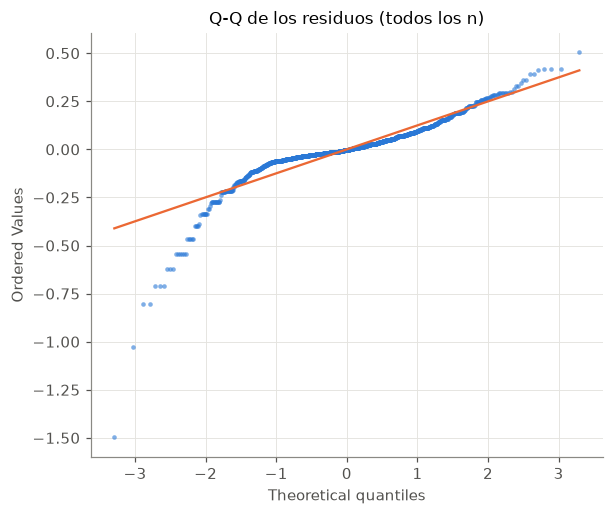

In [7]:
res_todos = r_todos.resid
W, p = stats.shapiro(res_todos)
print(f"Shapiro-Wilk, residuos de todos los n: W = {W:.4f}, p-valor = {p:.2e}")

fig, ax = plt.subplots(figsize=(6, 5))
stats.probplot(res_todos, dist="norm", plot=ax)
puntos, recta = ax.get_lines()
puntos.set(color=AZUL, markersize=3, alpha=0.6, markeredgewidth=0)
recta.set(color=NARANJA, linewidth=1.5)
ax.set_title("Q-Q de los residuos (todos los n)")
plt.show()

Ahora el test con los residuos de cada $n$ por separado (calculados con el mismo ajuste de todos los $n$), junto con su asimetría.

In [8]:
b0_hat, b1_hat = r_todos.params
filas = []
for m in ns:
    res_m = np.log(sn_tamanos[m]) - (b0_hat + b1_hat * np.log(m))
    W_m, p_m = stats.shapiro(res_m)
    filas.append({"n": m, "W": W_m, "p-valor": p_m, "¿rechaza al 5 %?": p_m < 0.05,
                  "asimetría": stats.skew(res_m)})
tabla_41d = pd.DataFrame(filas).set_index("n")
tabla_41d.round(4)

,W,p-valor,¿rechaza al 5 %?,asimetría
n,,,,
10,0.9346,0.0000,True,-1.1914
20,0.9895,0.1524,False,-0.1408
50,0.9940,0.5985,False,0.0910
100,0.9899,0.1718,False,-0.3266
200,0.9914,0.2807,False,-0.1898
500,0.9963,0.9128,False,-0.0953
1000,0.9950,0.7485,False,-0.0614


Con todos los residuos juntos, Shapiro–Wilk da $W = 0{,}824$ y un p-valor de $10^{-36}$, así que rechaza. En el QQ-plot el centro es muy plano y las colas son largas, sobre todo la izquierda, que llega a $-1{,}5$: la mayoría de los residuos son de $n$ grandes y están muy cerca de 0, y los de $n$ chicos están mucho más dispersos.

Con cada $n$ por separado, el test solo rechaza con $n = 10$ ($W = 0{,}935$, asimetría $-1{,}19$). Para $n = 20, \dots, 1000$ los p-valores van de $0{,}15$ a $0{,}91$ y no rechaza. Dentro de cada $n$ la normalidad es razonable porque $S_n$ es aproximadamente normal, y como su desvío relativo es chico el logaritmo casi no le cambia la forma. Con $n = 10$ el desvío relativo es $0{,}25$ ($S_{10}$ es un entero entre 0 y 45), y el logaritmo estira la cola izquierda, que es la de los valores chicos.

Entonces la normalidad se cumple aproximadamente dentro de cada $n \geq 20$, pero no se cumple el supuesto del modelo, que pide errores $N(0, \sigma^2)$ con el mismo $\sigma$ para todos los $n$. La diferencia entre los dos resultados se explica porque los residuos juntos mezclan 7 grupos con desvíos muy distintos (lo que vimos en el c) y con medias distintas de 0, porque la recta no pasa exactamente por la media de cada $n$ (lo que vimos en el b). Una mezcla de normales con distintas varianzas no es normal: tiene el centro más concentrado y las colas más pesadas, y con 1400 datos el test lo detecta.

Como cada $n$ tiene 200 observaciones, aunque los errores no sean normales los estimadores son aproximadamente normales por el TCL, así que la falta de normalidad en sí no es un problema grave para los intervalos y tests. El problema principal es la varianza no constante del c).

## Ejercicio 4.2: Complejidad de quicksort

Ajuste $Q_n/n = \beta_0 + \beta_1 \ln n + \epsilon$ usando todos los $n$.

### a)
A partir de la fórmula de $E(Q_n)$ y de $H_n \approx \ln n + \gamma$ ($\gamma \approx 0{,}5772$), ¿qué valores de $\beta_0$ y $\beta_1$ espera? ¿Los intervalos de confianza de nivel $0{,}95$ los contienen?

---

Como $\mathrm{E}(Q_n) = 2(n+1)H_n - 4n$, dividiendo por $n$
$$\frac{\mathrm{E}(Q_n)}{n} = 2\left(1 + \frac{1}{n}\right)H_n - 4.$$
Para $n$ grande $1 + 1/n \approx 1$ y $H_n \approx \ln n + \gamma$, así que
$$\frac{\mathrm{E}(Q_n)}{n} \approx 2\ln n + 2\gamma - 4.$$
Esperamos $\beta_1 = 2$ y $\beta_0 = 2\gamma - 4 \approx -2{,}846$.

En la tabla de abajo, con todos los $n$ obtuvimos $\hat\beta_1 = 1{,}870$, con intervalo $[1{,}850;\ 1{,}890]$, y $\hat\beta_0 = -2{,}028$, con intervalo $[-2{,}125;\ -1{,}931]$. Ninguno de los dos intervalos contiene al valor esperado: la pendiente queda por debajo de 2 y el intercepto por encima de $-2{,}846$.

In [9]:
# %% 4.2 a) Ajuste usando todos los n
gamma = np.euler_gamma
b0_esperado = 2 * gamma - 4
b1_esperado = 2.0

# Preparación de datos para Q_n / n = b0 + b1 ln(n) + e
def datos_quicksort(ms):
    x = np.concatenate([np.full(len(qn_tamanos[m]), np.log(m)) for m in ms])
    y = np.concatenate([np.array(qn_tamanos[m]) / m for m in ms])
    return x, y

x_q_todos, y_q_todos = datos_quicksort(ns)
r_q_todos = sm.OLS(y_q_todos, sm.add_constant(x_q_todos)).fit()

def fila_regresion_42(r, nombre, b0_esp, b1_esp):
    b0, b1 = r.params
    ic_b0, ic_b1 = r.conf_int(alpha=0.05)
    contiene_b0 = ic_b0[0] <= b0_esp <= ic_b0[1]
    contiene_b1 = ic_b1[0] <= b1_esp <= ic_b1[1]
    return {
        "Ajuste": nombre,
        "N": int(r.nobs),
        "β̂0": b0,
        "IC 95 % β0": f"[{ic_b0[0]:.4f}, {ic_b0[1]:.4f}]",
        "¿Contiene β0?": contiene_b0,
        "β̂1": b1,
        "IC 95 % β1": f"[{ic_b1[0]:.4f}, {ic_b1[1]:.4f}]",
        "¿Contiene β1?": contiene_b1,
    }

tabla_42a = pd.DataFrame([fila_regresion_42(r_q_todos, "todos los n", b0_esperado, b1_esperado)]).set_index("Ajuste")
print(f"Valores esperados teóricos: β0 = {b0_esperado:.4f}, β1 = {b1_esperado:.4f}")
display(tabla_42a)

Valores esperados teóricos: β0 = -2.8456, β1 = 2.0000


,N,β̂0,IC 95 % β0,¿Contiene β0?,β̂1,IC 95 % β1,¿Contiene β1?
Ajuste,,,,,,,
todos los n,1400,-2.027783,"[-2.1245, -1.9310]",False,1.869949,"[1.8500, 1.8899]",False


### b)
Si no los contienen, explique por qué. *(Ayuda: compare el valor exacto de $E(Q_n)/n$ con el valor teórico de la recta según la aproximación usada, para $n = 10$ y para $n = 1000$)*. Repita el ajuste usando solo $n \ge 100$: ¿qué cambia?

---

La aproximación de la recta tira dos cosas: el factor $1 + 1/n$ y la diferencia entre $H_n$ y $\ln n + \gamma$. Las dos hacen que el valor exacto de $\mathrm{E}(Q_n)/n$ quede por encima de la recta $2\ln n + 2\gamma - 4$, y la diferencia es grande para $n$ chico: en la primera tabla de abajo vale $0{,}684$ con $n = 10$ y $0{,}016$ con $n = 1000$.

Como esa diferencia es grande en los $n$ chicos y casi 0 en los grandes, los datos de $n$ chico quedan por encima de la recta asintótica y la recta ajustada queda menos inclinada: la pendiente baja y el intercepto sube. Entonces los intervalos no fallan por azar, sino porque la recta asintótica no describe bien a $\mathrm{E}(Q_n)/n$ cuando se incluyen $n$ chicos.

Con $n \geq 100$ la diferencia con la recta asintótica es mucho más chica y las estimaciones se acercan a los valores esperados. $\hat\beta_1 = 1{,}952$, con intervalo $[1{,}903;\ 2{,}001]$, que ahora sí contiene al 2. $\hat\beta_0 = -2{,}502$ también se acerca a $-2{,}846$, pero su intervalo $[-2{,}790;\ -2{,}215]$ todavía no lo contiene. El intercepto es el valor de la recta en $\ln n = 0$, que está lejos de los datos ($\ln n$ va de $4{,}6$ a $6{,}9$), así que un error chico en la pendiente se agranda al extender la recta hasta 0.

Además, con $n \geq 100$ hay menos observaciones y el rango de $\ln n$ es más chico, así que los intervalos son más anchos: el de $\beta_1$ pasa de medir $0{,}04$ a medir $0{,}10$. Parte de que ahora contenga al 2 se debe a eso, porque la diferencia con la recta asintótica, aunque chica, sigue bajando la pendiente.

In [10]:
# %% 4.2 b) Comparación y ajuste para n >= 100
def H_n(m):
    return np.sum(1.0 / np.arange(1, m + 1))

def eq_sobre_n_exacto(m):
    return 2.0 * (m + 1.0) * H_n(m) / m - 4.0

def recta_teorica(m):
    return b0_esperado + b1_esperado * np.log(m)

# Comparación para n=10 y n=1000
comp_n = [10, 1000]
df_comp = pd.DataFrame({
    "n": comp_n,
    "E(Q_n)/n (exacto)": [eq_sobre_n_exacto(m) for m in comp_n],
    "Recta teórica": [recta_teorica(m) for m in comp_n],
})
df_comp["Diferencia"] = df_comp["E(Q_n)/n (exacto)"] - df_comp["Recta teórica"]
display(df_comp.set_index("n").round(4))

# Ajuste con n >= 100
x_q_100, y_q_100 = datos_quicksort([m for m in ns if m >= 100])
r_q_100 = sm.OLS(y_q_100, sm.add_constant(x_q_100)).fit()

tabla_42b = pd.DataFrame([fila_regresion_42(r_q_100, "n >= 100", b0_esperado, b1_esperado)]).set_index("Ajuste")
display(tabla_42b)

,E(Q_n)/n (exacto),Recta teórica,Diferencia
n,,,
10,2.4437,1.7596,0.6841
1000,10.9859,10.9699,0.0160


,N,β̂0,IC 95 % β0,¿Contiene β0?,β̂1,IC 95 % β1,¿Contiene β1?
Ajuste,,,,,,,
n >= 100,800,-2.50246,"[-2.7904, -2.2146]",False,1.95195,"[1.9025, 2.0014]",True


### c)
Calcule el desvío de $Q_n / n$ para cada $n$ y compárelo con lo obtenido en 4.1 c).

---

En la tabla de abajo, el desvío de $Q_n/n$ se mantiene más o menos constante: está entre $0{,}42$ y $0{,}71$, y de $n = 50$ en adelante entre $0{,}56$ y $0{,}71$. Tiene sentido porque $\operatorname{Var}(Q_n) = 7n^2 - 4(n+1)^2 H^{(2)}_n - 2(n+1)H_n + 13n$ crece como $n^2$ (como $H^{(2)}_n \to \pi^2/6$, el término principal es $(7 - 2\pi^2/3)\,n^2$). Al dividir por $n$ la varianza tiende a una constante, y el desvío a $\sqrt{7 - 2\pi^2/3} \approx 0{,}65$.

Es muy distinto del 4.1 c. Ahí el desvío de $\ln S_n$ bajaba $13{,}5$ veces entre $n = 10$ y $n = 1000$, y acá el mayor desvío es solo $1{,}7$ veces el menor. Entonces en este modelo el supuesto de varianza constante se cumple bastante mejor.

In [11]:
# %% 4.2 c) Varianza de Q_n / n
filas_qc = []
for m in ns:
    q_norm = np.array(qn_tamanos[m]) / m
    filas_qc.append({
        "n": m, 
        "desvío de Q_n/n": q_norm.std(ddof=1)
    })
tabla_42c = pd.DataFrame(filas_qc).set_index("n")
display(tabla_42c.round(4))

,desvío de Q_n/n
n,
10,0.4169
20,0.4899
50,0.6195
100,0.6088
200,0.5588
500,0.7070
1000,0.6055


### d)
Repita 4.1 d) con los residuos de este ajuste. ¿La causa del rechazo es la misma?

---

Con todos los residuos juntos el test rechaza ($W = 0{,}961$, p-valor $8 \cdot 10^{-19}$), igual que en el 4.1 d. Pero ahora también rechaza con cada $n$ por separado, con p-valores menores que $0{,}001$ en los siete casos. Entonces la causa del rechazo no es la misma.

En el 4.1 los residuos de cada $n$ eran aproximadamente normales, y el rechazo venía de juntar grupos con varianzas muy distintas. Acá la varianza es parecida en todos los $n$ (lo que vimos en el c), así que juntar los grupos no es el problema. Lo que pasa es que $Q_n$ no es normal para ningún $n$: es asimétrica a derecha, igual que vimos para $Q_{100}$ en el 3.1. En el QQ-plot los puntos quedan por encima de la recta en los dos extremos, que es la forma de una cola derecha larga.

Además el test sigue rechazando con $n = 1000$, así que la asimetría no desaparece con $n$ grande. Por eso, a diferencia del 4.1, el rechazo no se arreglaría separando por $n$, porque viene de la forma de la distribución de $Q_n$.

Shapiro-Wilk, residuos (todos los n): W = 0.9613, p-valor = 7.67e-19


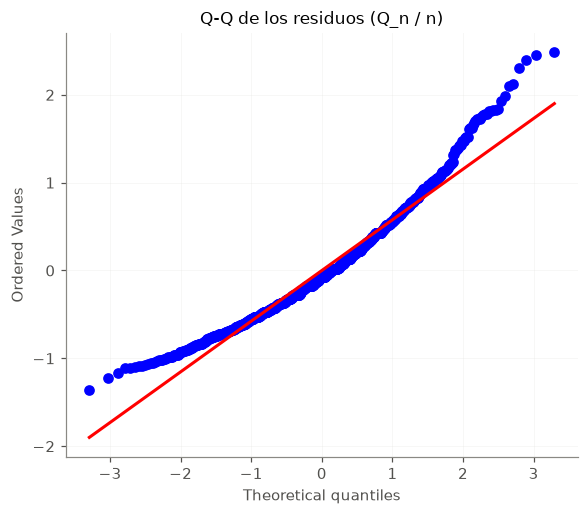

,W,p-valor,¿rechaza al 5 %?
n,,,
10,0.9073,0.0000,True
20,0.9113,0.0000,True
50,0.9425,0.0000,True
100,0.9504,0.0000,True
200,0.9529,0.0000,True
500,0.9657,0.0001,True
1000,0.9626,0.0000,True


In [12]:
# %% 4.2 d) Normalidad de los residuos
res_q_todos = r_q_todos.resid
W_q, p_q = stats.shapiro(res_q_todos)
print(f"Shapiro-Wilk, residuos (todos los n): W = {W_q:.4f}, p-valor = {p_q:.2e}")

fig, ax = plt.subplots(figsize=(6, 5))
stats.probplot(res_q_todos, dist="norm", plot=ax)
ax.set_title("Q-Q de los residuos (Q_n / n)")
ax.grid(alpha=0.3)
plt.show()

# Shapiro-Wilk por cada n
filas_qd = []
for m in ns:
    res_m = res_q_todos[x_q_todos == np.log(m)]
    W_m, p_m = stats.shapiro(res_m)
    filas_qd.append({"n": m, "W": W_m, "p-valor": p_m, "¿rechaza al 5 %?": p_m < 0.05})

tabla_42d = pd.DataFrame(filas_qd).set_index("n")
display(tabla_42d.round(4))

## Ejercicio 4.4: ¿Cuándo conviene insertion sort?

Para $n = 100$ y $k = 5, 10, 15, 20, 25, 30, 40$, genere 300 listas nuevas por cada $k$. En cada lista defina $Y = 1$ si $C_{100} < Q_{100}$ (insertion sort usa menos comparaciones que quicksort) e $Y = 0$ si no.

### Generación de las listas

Usamos `medir` de `codigo_base.py`, que corre insertion sort y quicksort (pivote en el primer elemento) sobre **las mismas** listas, así cada lista da un par $(C_{100}, Q_{100})$.

In [13]:
ks = [5, 10, 15, 20, 25, 30, 40]
N_k = 300

filas = []
for k in ks:
    filas += medir("insertion_vs_quick", ["insertion", "quick_primero"], n=100, N=N_k, rng=rng, k=k)

# una fila por lista, con C (comparaciones de insertion) y Q (comparaciones de quicksort)
datos = (pd.DataFrame(filas)
         .pivot_table(index=["k", "lista"], columns="algoritmo", values="comparaciones")
         .rename(columns={"insertion": "C", "quick_primero": "Q"})
         .reset_index())
datos["Y"] = (datos["C"] < datos["Q"]).astype(int)

print(f"{len(datos)} listas ({N_k} por cada k)")
print(f"empates C = Q: {(datos['C'] == datos['Q']).sum()} (cuentan como Y = 0)")
datos.head()

2100 listas (300 por cada k)
empates C = Q: 1 (cuentan como Y = 0)


algoritmo,k,lista,C,Q,Y
0,5,0,372.0,2966.0,1
1,5,1,334.0,2594.0,1
2,5,2,506.0,2209.0,1
3,5,3,354.0,2405.0,1
4,5,4,382.0,2288.0,1


---

### a)

Grafique la proporción de $Y = 1$ en función de $k$. ¿Por qué insertion sort gana con listas casi ordenadas? Ajuste una regresión lineal de $Y$ en función de $k$: ¿por qué no es un modelo adecuado?

recta: Y = 1.199 + (-0.0342) k
  predicción en k =  0:  1.199
  predicción en k = 40: -0.168


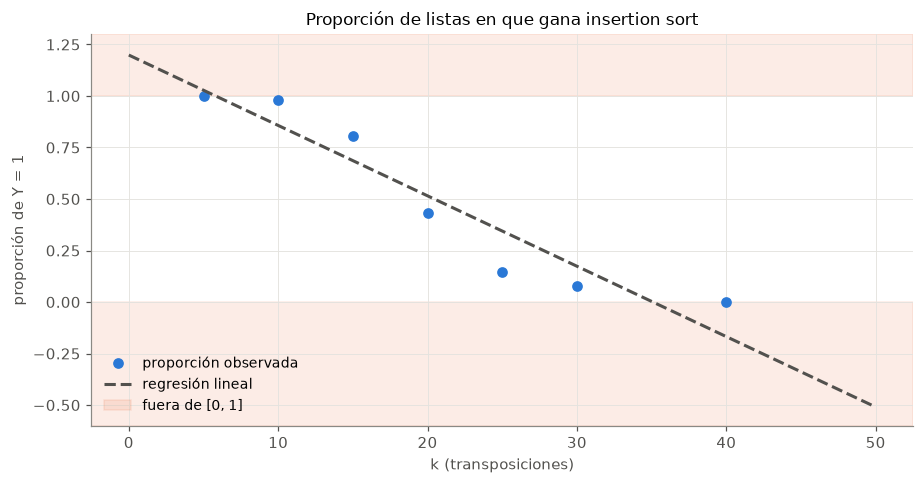

In [14]:
por_k = datos.groupby("k").agg(p=("Y", "mean"))

# Regresión lineal de Y en k (cuadrados mínimos)
X = sm.add_constant(datos["k"])
lineal = sm.OLS(datos["Y"], X).fit()
a_lin, b_lin = lineal.params
print(f"recta: Y = {a_lin:.3f} + ({b_lin:.4f}) k")
for k0 in [0, 40]:
    print(f"  predicción en k = {k0:>2}: {a_lin + b_lin * k0:6.3f}")

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(por_k.index, por_k["p"], "o", color=AZUL, label="proporción observada")
grilla = np.linspace(0, 50, 200)
ax.plot(grilla, a_lin + b_lin * grilla, "--", color=GRIS, label="regresión lineal")
ax.axhspan(1, 1.3, color=NARANJA, alpha=0.12)
ax.axhspan(-0.6, 0, color=NARANJA, alpha=0.12, label="fuera de [0, 1]")
ax.set_ylim(-0.6, 1.3)
ax.set_xlabel("k (transposiciones)")
ax.set_ylabel("proporción de Y = 1")
ax.set_title("Proporción de listas en que gana insertion sort")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()


La proporción de listas en las que gana insertion sort es $1$ con $k = 5$, $0{,}98$ con $k = 10$ y $0{,}80$ con $k = 15$, cae a $0{,}43$ con $k = 20$ y después sigue bajando hasta $0$ con $k = 40$. Entre $k = 15$ y $k = 25$ es donde cambia qué algoritmo conviene.

Insertion sort gana con listas casi ordenadas porque sus comparaciones dependen de cuántas inversiones tiene la lista: como vimos en el 3.3 c, $C_{100} = S_{100} + 99 - M$, y $S_{100}$ es la cantidad de inversiones. Una lista casi ordenada tiene pocas inversiones (cada transposición agrega en promedio $(n-1)(2n-1)/(3n) \approx 66$), así que con $k = 5$ insertion sort hace unas $99 + 5 \cdot 66 \approx 430$ comparaciones.

Quicksort con pivote en el primer elemento hace lo contrario. En una lista casi ordenada el primer elemento suele ser el mínimo del subarreglo, así que la partición deja todo de un lado y en cada paso se saca un solo elemento, como en la lista ordenada, que es el peor caso ($4950$ comparaciones). A medida que $k$ crece la lista se parece a una permutación uniforme, $C_{100}$ sube hacia $\approx 2570$ y $Q_{100}$ baja hacia $647{,}85$.

La regresión lineal da $\hat Y = 1{,}199 - 0{,}0342\,k$ y no es un modelo adecuado. Como $Y$ solo vale 0 o 1, lo que se está modelando es $P(Y = 1 \mid k)$, que tiene que estar entre 0 y 1, y la recta se sale de ese rango: predice $1{,}2$ para $k = 0$ y $-0{,}17$ para $k = 40$. Además las proporciones tienen forma de S (planas cerca de 1, una caída fuerte entre 15 y 25 y planas cerca de 0), y una recta no puede seguir esa forma: subestima la proporción en $k = 10$ y $15$ y la sobreestima en $k = 25$ y $30$.

Por otro lado, $\operatorname{Var}(Y \mid k) = \pi(k)(1 - \pi(k))$ cambia con $k$ (es casi 0 en los extremos y máxima cuando $\pi = 0{,}5$), así que no se cumple el supuesto de varianza constante, y los errores solo pueden tomar dos valores para cada $k$, así que tampoco son normales.

---

### b)

Ajuste el modelo logístico, con $\pi(k) = P(Y = 1 \mid k)$ y `statsmodels.api.Logit`:
$$\log\frac{\pi(k)}{1 - \pi(k)} = \beta_0 + \beta_1 k.$$
Construya un intervalo de confianza de Wald de nivel 0,95 para $\beta_1$ e interprete $e^{\hat\beta_1}$. Compare las probabilidades ajustadas con las proporciones observadas.

β̂0 = 6.2520
β̂1 = -0.3172   EE = 0.0138   IC Wald 95%: [-0.3443, -0.2901]

e^β̂1 = 0.7282   IC 95%: [0.7087, 0.7482]

    observada  ajustada
k                      
5       1.000     0.991
10      0.980     0.956
15      0.803     0.817
20      0.430     0.477
25      0.147     0.157
30      0.077     0.037
40      0.000     0.002


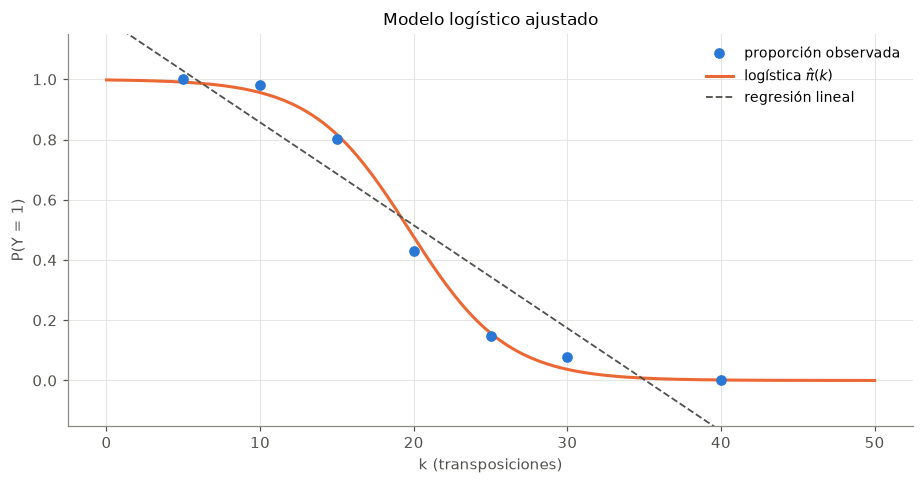

In [15]:
logit = sm.Logit(datos["Y"], X).fit(disp=0)
b0, b1 = logit.params
ic_b1 = logit.conf_int(alpha=0.05).loc["k"]

print(f"β̂0 = {b0:.4f}")
print(f"β̂1 = {b1:.4f}   EE = {logit.bse['k']:.4f}   IC Wald 95%: [{ic_b1[0]:.4f}, {ic_b1[1]:.4f}]")
print(f"\ne^β̂1 = {np.exp(b1):.4f}   IC 95%: [{np.exp(ic_b1[0]):.4f}, {np.exp(ic_b1[1]):.4f}]")

# Probabilidades ajustadas vs proporciones observadas
por_k["ajustada"] = logit.predict(sm.add_constant(pd.Series(ks, name="k"), has_constant="add")).to_numpy()
print()
print(por_k[["p", "ajustada"]].rename(columns={"p": "observada"}).round(3).to_string())

def pi_logit(k):
    return 1 / (1 + np.exp(-(b0 + b1 * k)))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(por_k.index, por_k["p"], "o", color=AZUL, label="proporción observada", zorder=3)
ax.plot(grilla, pi_logit(grilla), color=NARANJA, label=r"logística $\hat\pi(k)$")
ax.plot(grilla, a_lin + b_lin * grilla, "--", color=GRIS, lw=1.2, label="regresión lineal")
ax.set_ylim(-0.15, 1.15)
ax.set_xlabel("k (transposiciones)")
ax.set_ylabel("P(Y = 1)")
ax.set_title("Modelo logístico ajustado")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


El modelo logístico plantea que el logaritmo de las chances $\pi/(1-\pi)$ es una recta en $k$, lo cual hace que $\pi(k) = 1/(1 + e^{-(\beta_0 + \beta_1 k)})$ quede siempre entre 0 y 1 y tenga forma de S. Obtuvimos $\hat\beta_0 = 6{,}25$ y $\hat\beta_1 = -0{,}317$, con error estándar $0{,}0138$.

El intervalo de Wald es $\hat\beta_1 \pm 1{,}96 \cdot \mathrm{EE}(\hat\beta_1)$, que da $[-0{,}344;\ -0{,}290]$. No contiene al 0, así que $k$ tiene efecto sobre la probabilidad de que gane insertion sort, y el efecto es negativo: con más desorden gana menos.

$e^{\hat\beta_1} = 0{,}728$, lo cual significa que cada transposición más multiplica las chances de que gane insertion sort por $0{,}728$, es decir que las baja un $27\%$. Con el intervalo, el factor está entre $0{,}709$ y $0{,}748$. Por ejemplo, 5 transposiciones más multiplican las chances por $0{,}728^5 \approx 0{,}20$. Lo que se multiplica son las chances $\pi/(1-\pi)$ y no la probabilidad, por eso la probabilidad baja poco cuando está cerca de 1 o de 0 y mucho cerca de $0{,}5$.

Las probabilidades ajustadas siguen bien a las observadas: $0{,}991$ contra $1$ en $k = 5$, $0{,}817$ contra $0{,}803$ en $k = 15$, $0{,}477$ contra $0{,}430$ en $k = 20$ y $0{,}157$ contra $0{,}147$ en $k = 25$. Las diferencias más grandes están en $k = 30$, donde el modelo da $0{,}037$ y observamos $0{,}077$, y en $k = 10$, donde da $0{,}956$ y observamos $0{,}980$. Igual la logística describe bien la forma general, mucho mejor que la recta.

---

### c)

¿Para qué valor de $k$ el modelo estima que los dos algoritmos tienen la misma probabilidad de ganar? Exprese ese valor en función de $\beta_0$ y $\beta_1$, y estímelo.

In [16]:
k_star = -b0 / b1
print(f"k* = -β̂0 / β̂1 = {-b0:.4f} / {b1:.4f} = {k_star:.2f}")


k* = -β̂0 / β̂1 = -6.2520 / -0.3172 = 19.71


Los dos algoritmos tienen la misma probabilidad de ganar cuando $\pi(k) = 0{,}5$, es decir cuando las chances valen 1 y su logaritmo vale 0. Entonces $\beta_0 + \beta_1 k^* = 0$, y
$$k^* = -\frac{\beta_0}{\beta_1}.$$
Con los valores estimados, $k^* = -6{,}252 / (-0{,}3172) \approx 19{,}7$.

Tiene sentido con lo observado: con $k = 15$ gana insertion sort el $80\%$ de las veces y con $k = 20$ el $43\%$, así que el cruce está apenas antes de 20. Lo cual significa que para listas de 100 elementos conviene insertion sort si la lista tiene menos de unas 20 transposiciones, y quicksort con pivote en el primer elemento si tiene más.